# Tutorial de MLflow: seguimiento de experimentos

Documentación oficial completa: [MLflow Tracking](https://mlflow.org/docs/latest/ml/tracking/).

Este notebook sigue los pasos del tutorial de MLflow sobre la demanda de manzanas
([Hyperparameter tuning with child runs](https://mlflow.org/docs/latest/ml/traditional-ml/tutorials/hyperparameter-tuning/notebooks/hyperparameter-tuning-with-child-runs/)
y [Logging plots in MLflow](https://mlflow.org/docs/latest/ml/traditional-ml/tutorials/hyperparameter-tuning/notebooks/logging-plots-in-mlflow/)):

1. Configurar el almacén de seguimiento y crear un experimento.
2. Generar los datos sintéticos, analizando el algoritmo del tutorial y su versión mejorada.
3. Registrar a mano una ejecución: parámetros, métricas, conjunto de datos, gráfico y modelo.
4. Agrupar una búsqueda de hiperparámetros en una ejecución padre con ejecuciones hijas.
5. Consultar las ejecuciones desde código.

El uso de MLflow con un `Pipeline` de scikit-learn está en `02_mlflow-sklearn-pipeline.ipynb`.

In [1]:
import logging
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd

# El aviso sobre columnas enteras y valores faltantes no aplica: el generador no produce nulos.
warnings.filterwarnings("ignore", message=".*Inferred schema contains integer column.*")
# El entorno creado con uv no trae pip, y MLflow lo avisa cada vez que guarda un modelo.
logging.getLogger("mlflow.utils.environment").setLevel(logging.ERROR)

# Raiz de la actividad, se ejecute el notebook desde notebooks/ o desde la raiz.
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

# Almacen local: las ejecuciones van a una base SQLite y los artefactos a una carpeta.
# Ninguno de los dos se versiona.
mlflow.set_tracking_uri(f"sqlite:///{ROOT / 'mlflow.db'}")


def get_or_create_experiment(name, description):
    """Devuelve el id del experimento, creandolo si no existe."""
    experiment = mlflow.get_experiment_by_name(name)
    if experiment is not None:
        return experiment.experiment_id
    return mlflow.create_experiment(
        name,
        artifact_location=(ROOT / "mlartifacts").as_uri(),
        tags={"mlflow.note.content": description, "project": "apples-demand"},
    )


print("MLflow", mlflow.__version__)
print("Tracking URI:", mlflow.get_tracking_uri().replace(str(ROOT), "<raiz>"))

MLflow 3.17.1
Tracking URI: sqlite:///<raiz>/mlflow.db


## 1. Experimento

Un experimento agrupa ejecuciones comparables entre sí. El tutorial levanta un servidor
(`mlflow server`) y apunta el cliente a `http://127.0.0.1:8080`. Aquí el cliente escribe
directo en una base SQLite local, que es el almacén por defecto de MLflow 3 y no exige
tener un proceso corriendo para ejecutar el notebook.

In [2]:
experiment_id = get_or_create_experiment(
    "apples-demand-tutorial",
    "Tutorial de MLflow: pronostico de demanda de manzanas con datos sinteticos.",
)
mlflow.set_experiment(experiment_id=experiment_id)
print("Experimento:", experiment_id)

2026/10/13 08:39:17 INFO mlflow.store.db.utils: Creating initial MLflow database tables...


2026/10/13 08:39:17 INFO mlflow.store.db.utils: Updating database tables


Experimento: 1


## 2. Datos sintéticos

### 2.1 El generador del tutorial, tal como está publicado

La función `generate_apple_sales_data_with_promo_adjustment` se copió sin cambios en
`mlflow_workshop.tutorial_data`. Con las versiones actuales de pandas no llega a ejecutarse.

In [3]:
from mlflow_workshop.tutorial_data import generate_apple_sales_data_with_promo_adjustment

print("pandas", pd.__version__)
try:
    generate_apple_sales_data_with_promo_adjustment(base_demand=1000, n_rows=5000)
except TypeError as error:
    print("El generador del tutorial falla:", error)

pandas 3.0.6
El generador del tutorial falla: NDFrame.fillna() got an unexpected keyword argument 'method'


`fillna(method="bfill")` se eliminó en pandas 3. Ese es el defecto visible, pero no el único
ni el más importante. El análisis completo está en
[`docs/02_synthetic-data-review.md`](../docs/02_synthetic-data-review.md); aquí se comprueba
el que más cambia el resultado.

### 2.2 La estacionalidad del tutorial vale cero

El tutorial modela dos cosechas al año sumando dos senos desfasados seis meses. Dos senos
con medio ciclo de diferencia se cancelan: $\sin(x) + \sin(x - \pi) = 0$. La columna
`harvest_effect` es cero todos los meses, así que ni el precio ni la demanda tienen la
estacionalidad que el comentario del código promete.

Maximo absoluto del efecto de cosecha en el tutorial: 2.220446049250313e-16


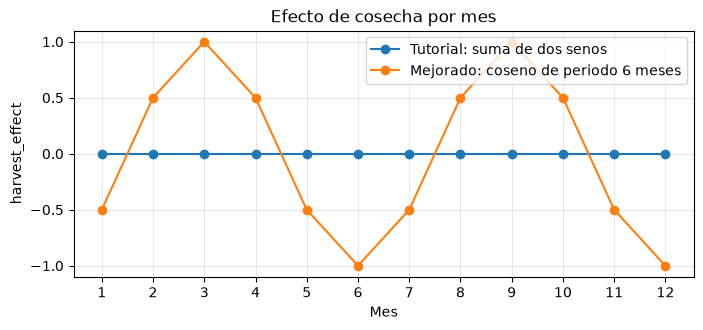

In [4]:
months = np.arange(1, 13)
tutorial_harvest = np.sin(2 * np.pi * (months - 3) / 12) + np.sin(2 * np.pi * (months - 9) / 12)
improved_harvest = np.cos(2 * np.pi * (months - 3) / 6)

print("Maximo absoluto del efecto de cosecha en el tutorial:", np.abs(tutorial_harvest).max())

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(months, tutorial_harvest, marker="o", label="Tutorial: suma de dos senos")
ax.plot(months, improved_harvest, marker="o", label="Mejorado: coseno de periodo 6 meses")
ax.set_xticks(months)
ax.set_xlabel("Mes")
ax.set_ylabel("harvest_effect")
ax.set_title("Efecto de cosecha por mes")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

### 2.3 El generador mejorado

`generate_apple_sales_data` conserva las columnas de salida del tutorial y corrige los
defectos encontrados. Con `keep_components=True` devuelve además cuánto aporta cada factor
a la demanda, que es la verdad contra la que se puede validar un modelo.

In [5]:
from mlflow_workshop import TARGET_COLUMN, generate_apple_sales_data

data = generate_apple_sales_data(n_rows=5000, base_demand=1000)
data.head()

,date,average_temperature,rainfall,weekend,holiday,price_per_kg,promo,previous_days_demand,competitor_price_per_kg,marketing_intensity,demand
0,2011-04-25,31.278603,1.851679,0,0,2.599977,1,1466.640528,2.251595,0.616025,1123.677119
1,2011-04-26,12.483144,0.033727,0,0,0.634884,1,1123.677119,0.789789,0.636920,1261.501327
2,2011-04-27,30.660568,1.473259,0,0,0.648268,1,1261.501327,0.831791,0.779411,1371.049138
3,2011-04-28,24.168084,6.409454,0,0,2.517236,1,1371.049138,1.020819,0.668592,1012.490433
4,2011-04-29,20.692022,0.762351,0,0,0.657563,1,1012.490433,2.687909,0.630717,1224.707586


In [6]:
components = generate_apple_sales_data(n_rows=5000, base_demand=1000, keep_components=True)

checks = {
    "Dos llamadas devuelven lo mismo": data.equals(generate_apple_sales_data(n_rows=5000, base_demand=1000)),
    "Sin valores nulos": int(data.isna().sum().sum()) == 0,
    "El rezago es la demanda final del dia anterior": bool(
        np.allclose(data["previous_days_demand"].iloc[1:], data[TARGET_COLUMN].iloc[:-1])
    ),
    "La estacionalidad existe": bool(components["seasonality_effect"].abs().max() > 0),
    "Primer dia": data["date"].iloc[0].date(),
    "Ultimo dia": data["date"].iloc[-1].date(),
}
pd.Series(checks, name="resultado").to_frame()

,resultado
Dos llamadas devuelven lo mismo,True
Sin valores nulos,True
El rezago es la demanda final del dia anterior,True
La estacionalidad existe,True
Primer dia,2011-04-25
Ultimo dia,2024-12-31


In [7]:
# Aporte medio de cada factor a la demanda, en unidades vendidas por dia.
effect_columns = [column for column in components.columns if column.endswith("_effect") and column != "harvest_effect"]
components[effect_columns].agg(["mean", "std", "min", "max"]).T.round(1)

,mean,std,min,max
price_effect,-87.0,37.3,-162.2,-12.6
seasonality_effect,-0.6,35.4,-50.0,50.0
promo_effect,57.2,90.4,0.0,200.0
weekend_effect,85.7,135.5,0.0,300.0
holiday_effect,4.6,25.8,0.0,150.0
rainfall_effect,-14.8,14.7,-134.9,-0.0
competitor_price_effect,-25.0,25.0,-50.0,-0.0
marketing_effect,42.8,12.1,4.1,77.7


## 3. Registrar una ejecución a mano

La partición es temporal: se entrena con el pasado y se evalúa con el último 20 % de los
días. El tutorial usa `train_test_split` aleatorio, que mezcla días futuros en el
entrenamiento; con una variable como `previous_days_demand` eso filtra el objetivo y
devuelve métricas mejores de lo que el modelo logrará al usarse.

Igual que en el tutorial, el modelo es un `RandomForestRegressor` sobre las columnas
numéricas, sin la fecha.

In [8]:
from mlflow.models import infer_signature
from sklearn.ensemble import RandomForestRegressor

from mlflow_workshop import regression_metrics, split_by_time

X_train, X_test, y_train, y_test = split_by_time(data.drop(columns=["date"]), TARGET_COLUMN, test_size=0.2)
print("Entrenamiento:", X_train.shape, "| Prueba:", X_test.shape)

# El conjunto de datos tambien se registra: queda su esquema, su tamano y una huella de su contenido.
train_dataset = mlflow.data.from_pandas(
    pd.concat([X_train, y_train], axis=1), targets=TARGET_COLUMN, name="apples-train"
)
test_dataset = mlflow.data.from_pandas(
    pd.concat([X_test, y_test], axis=1), targets=TARGET_COLUMN, name="apples-test"
)

Entrenamiento: (4000, 9) | Prueba: (1000, 9)


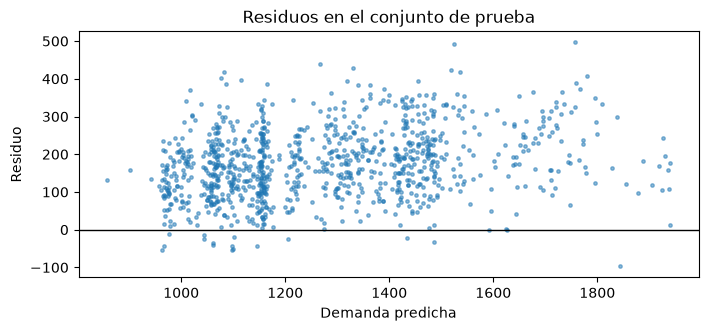

test_rmse    198.132
test_mae     176.878
test_r2        0.424
test_bias    175.655
dtype: float64

In [9]:
params = {"n_estimators": 100, "max_depth": 6, "min_samples_split": 10, "random_state": 42}

# MLflow 3 serializa los modelos de scikit-learn con skops, que solo carga tipos de una lista
# de confianza. La estructura interna de los arboles no esta en ella y hay que declararla.
TRUSTED_TYPES = ["sklearn.tree._tree.Tree"]

with mlflow.start_run(run_name="rf-baseline") as run:
    model = RandomForestRegressor(**params, n_jobs=-1).fit(X_train, y_train)
    predictions = model.predict(X_test)

    mlflow.log_params(params)
    mlflow.log_metrics(regression_metrics(y_train, model.predict(X_train), prefix="train_"))
    metrics = regression_metrics(y_test, predictions, prefix="test_")
    # Sesgo: cuanto se queda corta, en promedio, la prediccion frente a la demanda real.
    metrics["test_bias"] = float((y_test - predictions).mean())
    mlflow.log_metrics(metrics)
    mlflow.set_tags({"stage": "baseline", "split": "temporal"})
    mlflow.log_input(train_dataset, context="training")
    mlflow.log_input(test_dataset, context="testing")

    # Un grafico se guarda como artefacto de la ejecucion.
    fig, ax = plt.subplots(figsize=(8, 3.2))
    ax.scatter(predictions, y_test - predictions, s=6, alpha=0.5)
    ax.axhline(0, color="black", linewidth=1)
    ax.set_xlabel("Demanda predicha")
    ax.set_ylabel("Residuo")
    ax.set_title("Residuos en el conjunto de prueba")
    mlflow.log_figure(fig, "plots/residuals.png")
    plt.show()

    # El modelo se guarda con su firma (esquema de entrada y salida) y un ejemplo de entrada.
    model_info = mlflow.sklearn.log_model(
        model,
        name="model",
        signature=infer_signature(X_train, model.predict(X_train)),
        input_example=X_train.head(3),
        skops_trusted_types=TRUSTED_TYPES,
    )

baseline_run_id = run.info.run_id
pd.Series(metrics).round(3)

### 3.1 Lo que la partición aleatoria esconde

El resultado es flojo, y el sesgo dice por qué: el modelo se queda corto casi siempre. La
demanda crece con la inflación y el conjunto de prueba son los días más recientes, con
niveles que el bosque no vio al entrenar; un árbol no extrapola una tendencia.

Para comprobarlo se registra el mismo modelo con la partición aleatoria del tutorial. Es el
uso más directo del seguimiento de experimentos: dos ejecuciones que solo difieren en una
decisión, comparadas con las mismas métricas.

In [10]:
from sklearn.model_selection import train_test_split

features, target = data.drop(columns=["date", TARGET_COLUMN]), data[TARGET_COLUMN]
Xr_train, Xr_test, yr_train, yr_test = train_test_split(features, target, test_size=0.2, random_state=42)

with mlflow.start_run(run_name="rf-baseline-random-split"):
    random_model = RandomForestRegressor(**params, n_jobs=-1).fit(Xr_train, yr_train)
    random_predictions = random_model.predict(Xr_test)
    random_metrics = regression_metrics(yr_test, random_predictions, prefix="test_")
    random_metrics["test_bias"] = float((yr_test - random_predictions).mean())
    mlflow.log_params(params)
    mlflow.log_metrics(random_metrics)
    mlflow.set_tags({"stage": "baseline", "split": "random"})

comparison = mlflow.search_runs(
    experiment_ids=[experiment_id], filter_string="tags.stage = 'baseline'", order_by=["start_time ASC"]
)
comparison[["tags.mlflow.runName", "tags.split", "metrics.test_rmse", "metrics.test_r2", "metrics.test_bias"]].round(3)

,tags.mlflow.runName,tags.split,metrics.test_rmse,metrics.test_r2,metrics.test_bias
0,rf-baseline,temporal,198.132,0.424,175.655
1,rf-baseline-random-split,random,129.400,0.768,3.172


Con la partición aleatoria el mismo modelo parece mucho mejor y sin sesgo, porque cada día
de prueba tiene vecinos en el entrenamiento. Esa métrica no describe lo que pasará al
pronosticar días futuros; la temporal sí. El segundo notebook resuelve el problema de fondo
dándole al modelo una variable de tendencia dentro del pipeline.

El modelo registrado se recupera por su URI y predice sin tener a mano el objeto original.

In [11]:
loaded_model = mlflow.pyfunc.load_model(model_info.model_uri)
pd.DataFrame({
    "real": y_test.head(5).round(1).to_numpy(),
    "prediccion": np.round(loaded_model.predict(X_test.head(5)), 1),
})

,real,prediccion
0,1290.5,1273.8
1,1473.7,1323.8
2,1810.3,1608.8
3,1914.3,1685.0
4,1389.6,1309.6


## 4. Ejecuciones anidadas

Una búsqueda de hiperparámetros produce muchas ejecuciones que solo tienen sentido juntas.
El tutorial las agrupa bajo una ejecución padre con `nested=True`. Aquí la búsqueda es una
rejilla pequeña recorrida a mano, para que se vea qué registra cada nivel:

- **Hija**: una combinación de hiperparámetros y sus métricas.
- **Padre**: la mejor combinación, su métrica y el modelo ganador.

In [12]:
from itertools import product

grid = {"n_estimators": [50, 150], "max_depth": [4, 8, 12]}

with mlflow.start_run(run_name="rf-grid-manual") as parent_run:
    mlflow.set_tags({"stage": "tuning", "split": "temporal"})
    mlflow.log_input(train_dataset, context="training")
    mlflow.log_input(test_dataset, context="testing")
    best = None

    for n_estimators, max_depth in product(grid["n_estimators"], grid["max_depth"]):
        child_params = {"n_estimators": n_estimators, "max_depth": max_depth, "min_samples_split": 10, "random_state": 42}
        with mlflow.start_run(run_name=f"rf-n{n_estimators}-d{max_depth}", nested=True):
            candidate = RandomForestRegressor(**child_params, n_jobs=-1).fit(X_train, y_train)
            child_metrics = regression_metrics(y_test, candidate.predict(X_test), prefix="test_")
            mlflow.log_params(child_params)
            mlflow.log_metrics(child_metrics)
        if best is None or child_metrics["test_rmse"] < best["metrics"]["test_rmse"]:
            best = {"params": child_params, "metrics": child_metrics, "model": candidate}

    mlflow.log_params({f"best_{key}": value for key, value in best["params"].items()})
    mlflow.log_metrics(best["metrics"])
    mlflow.sklearn.log_model(
        best["model"],
        name="model",
        signature=infer_signature(X_train, best["model"].predict(X_train)),
        input_example=X_train.head(3),
        skops_trusted_types=TRUSTED_TYPES,
    )

print("Mejor combinacion:", best["params"])
pd.Series(best["metrics"]).round(3)

Mejor combinacion: {'n_estimators': 150, 'max_depth': 12, 'min_samples_split': 10, 'random_state': 42}


test_rmse    191.804
test_mae     171.336
test_r2        0.460
dtype: float64

La evaluación de cada combinación se hizo contra el conjunto de prueba para mantener el
ejemplo corto. Elegir hiperparámetros así contamina la métrica final; la forma correcta,
con validación cruzada temporal dentro del entrenamiento, está en el segundo notebook.

## 5. Consultar las ejecuciones desde código

Lo que se ve en la interfaz también se puede consultar con `mlflow.search_runs`, que
devuelve un `DataFrame`.

In [13]:
children = mlflow.search_runs(
    experiment_ids=[experiment_id],
    filter_string=f"tags.mlflow.parentRunId = '{parent_run.info.run_id}'",
    order_by=["metrics.test_rmse ASC"],
)
children[[
    "tags.mlflow.runName", "params.n_estimators", "params.max_depth",
    "metrics.test_rmse", "metrics.test_mae", "metrics.test_r2",
]].round(3)

,tags.mlflow.runName,params.n_estimators,params.max_depth,metrics.test_rmse,metrics.test_mae,metrics.test_r2
0,rf-n150-d12,150,12,191.804,171.336,0.460
1,rf-n50-d12,50,12,191.823,171.085,0.460
2,rf-n150-d8,150,8,193.279,172.768,0.451
3,rf-n50-d8,50,8,193.647,172.925,0.449
4,rf-n150-d4,150,4,207.281,181.774,0.369
5,rf-n50-d4,50,4,207.697,182.277,0.367


In [14]:
client = mlflow.MlflowClient()
print("Artefactos de la ejecucion base:")
for artifact in client.list_artifacts(baseline_run_id, "plots"):
    print(" -", artifact.path)
print("Modelos registrados en el experimento:", len(mlflow.search_logged_models(experiment_ids=[experiment_id])))

Artefactos de la ejecucion base:
 - plots/residuals.png
Modelos registrados en el experimento: 2


## 6. Ver los resultados en la interfaz

Desde la raíz de la actividad:

```bash
uv run mlflow ui --backend-store-uri sqlite:///mlflow.db --port 5000
```

Las capturas de pantalla de este experimento están en el [`README`](../README.md) de la
actividad.